# Phase 4 · Optimisation experiments

**Question:** Phase 3 taught the warehouse to *predict*. Can better *decisions* — smarter routing and
smarter robot assignment, using those predictions — make the same 40 robots deliver faster, with fewer
late orders?

**Method:** run the simulated warehouse under different decision strategies on **exactly the same
orders, faults and hazards**, and compare the KPIs. No model is trained here: Phase 4 *uses* the
Phase 3 models (ETA and demand) inside the decisions.

Results come from `python scripts/run_experiments.py`, which writes `evaluation/reports/phase4/`.
This notebook only reads and explains them.

Sections: 1 The decisions → 2 Strategies → 3 Experimental design → 4 Results → 5 Paired comparison →
6 Consistency across seeds → 7 Conclusions.

## 1. The decisions being optimised

| Decision | Baseline rule (E2, today) | Optimised option |
|---|---|---|
| Which robot takes an order | the **nearest** free robot (straight line) | the robot the **ETA model predicts will finish first** (`eta`), or the best **combination** for all waiting orders (`global`, Hungarian algorithm) |
| Which route | **BFS**: fewest cells, traffic ignored | **A\*** with **traffic costs**: avoid occupied cells, busy one-way aisles, congested zones |
| When to re-plan | when blocked or a cell closes | also every 20 ticks with the current traffic (`replanning`) |
| Where idle robots wait | balanced parking | parking near the zone the **demand model** expects to be busy (`demand`) |
| When to top up batteries | below 70 % when no order waits | threshold follows the **demand forecast**: charge more in quiet hours, less in busy ones (`predictive`) |

## 2. Strategies (code)

| Component | File |
|---|---|
| Dijkstra / A\* planners | `ai/optimization/dijkstra.py`, `ai/optimization/astar.py` |
| Live traffic costs | `ai/optimization/traffic.py` |
| Cached route distances (reverse search) | `simulation/navigation/distance.py` |
| Assignment strategies | `ai/optimization/assignment.py` (random, eta, global) |
| ETA for candidate robots | `ai/optimization/eta_estimator.py` (Phase 3 model, `models/eta_v1.joblib`) |
| Demand-aware positioning, predictive charging | `ai/optimization/positioning.py` (Phase 3 demand models) |
| Switching strategies on the engine | `ai/optimization/optimizer.py` |
| Experiment definitions | `configs/experiments/E1.yaml … E5.yaml` |
| Runner and KPIs | `scripts/run_experiments.py`, `evaluation/simulation/metrics.py` |

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "evaluation").exists())
REPORT = ROOT / "evaluation" / "reports" / "phase4"
manifest = json.loads((REPORT / "manifest.json").read_text())
runs = pd.read_csv(REPORT / "runs.csv")
versus = pd.read_csv(REPORT / "vs_baseline.csv")
order = list(manifest["experiments"])
names = {e: manifest["experiments"][e]["name"] for e in order}
strategies = pd.DataFrame({e: manifest["experiments"][e]["strategies"] for e in order}).T
strategies.insert(0, "name", pd.Series(names))
strategies

,name,assignment,planner,traffic_aware,positioning,charging,replanning,traffic_weight
E1,Random assignment,random,bfs,False,balanced,threshold,False,NaN
E2,Heuristic baseline (nearest robot),nearest,bfs,False,balanced,threshold,False,NaN
E3,A* traffic-aware routing,nearest,astar,True,balanced,threshold,False,NaN
E4,AI prediction + assignment,eta,astar,True,balanced,threshold,False,NaN
E4b,Global assignment (Hungarian),global,astar,True,balanced,threshold,False,NaN
E5,Dynamic congestion + replanning + demand-aware...,eta,astar,True,demand,predictive,True,NaN
E3c,A* with gentle traffic costs (diagnostic),nearest,astar,True,balanced,threshold,False,0.25
E4c,"ETA-based assignment, BFS routes (diagnostic)",eta,bfs,False,balanced,threshold,False,NaN
E4d,"Global assignment, BFS routes (diagnostic)",global,bfs,False,balanced,threshold,False,NaN
E5b,Global assignment + demand-aware fleet,global,bfs,False,demand,predictive,False,NaN


## 3. Experimental design

- **Same conditions for every experiment.** Each run uses `independent_streams`: orders, faults and
  hazards come from their own random generators, so they are identical whatever the robots decide.
  Differences in the results come only from the strategies (*common random numbers*).
- **Several seeds.** Each experiment runs on the same 5 seeds (5 different simulated days), so we see
  the average effect *and* how consistent it is.
- **A full day per run** (24 simulated hours: quiet night, morning and afternoon peaks).
- **Paired comparison.** Each experiment is compared with E2 **on the same seed**, then averaged;
  "seeds improved" counts on how many of the days it was better.

KPIs (lower is better unless noted): average and 90th-percentile **completion time** (order placed →
delivered), **late orders %**, **throughput** (higher better), **wait for a robot**, **distance per
order**, **standoffs** (robots side-stepping to break a deadlock).

In [2]:
print(f"{manifest['seeds']} seeds x {manifest['hours']} simulated hours per experiment, "
      f"{len(runs)} runs, {manifest['seconds'] / 60:.0f} min of computing")
runs.groupby("experiment")[["orders_created", "orders_delivered"]].mean().reindex(order)

5 seeds x 24 simulated hours per experiment, 50 runs, 17 min of computing


,orders_created,orders_delivered
experiment,,
E1,2045.2,2034.4
E2,2042.4,2034.4
E3,2021.8,2011.2
E4,2012.2,2003.4
E4b,2040.2,2031.4
E5,2033.8,2026.0
E3c,2028.6,2018.2
E4c,2046.0,2038.2
E4d,2046.0,2037.6


The same number of orders was created in every experiment (identical demand), which confirms the fair setup.

## 4. Results (mean ± standard deviation over the seeds)

In [3]:
KPIS = {
    "avg_completion_ticks": ("Avg completion (ticks)", True),
    "p90_completion_ticks": ("90th pct completion (ticks)", True),
    "late_percent": ("Late orders (%)", True),
    "throughput_per_hour": ("Throughput (orders/h)", False),
    "avg_queue_ticks": ("Wait for a robot (ticks)", True),
    "distance_per_order_m": ("Distance per order (m)", True),
    "blocked_events": ("Standoffs", True),
}
mean = runs.groupby("experiment")[list(KPIS)].mean().reindex(order)
std = runs.groupby("experiment")[list(KPIS)].std().reindex(order)
table = mean.round(1).astype(str) + " ± " + std.round(1).astype(str)
table.columns = [KPIS[k][0] for k in table.columns]
table.index = [f"{e} {names[e]}" for e in order]
table

,Avg completion (ticks),90th pct completion (ticks),Late orders (%),Throughput (orders/h),Wait for a robot (ticks),Distance per order (m),Standoffs
E1 Random assignment,463.9 ± 33.4,1566.6 ± 183.8,23.1 ± 1.4,84.8 ± 1.3,271.6 ± 32.7,168.7 ± 0.8,250.2 ± 13.7
E2 Heuristic baseline (nearest robot),417.5 ± 48.3,1390.5 ± 317.5,20.6 ± 1.8,84.8 ± 1.1,236.1 ± 46.8,160.7 ± 1.6,246.0 ± 22.4
E3 A* traffic-aware routing,563.8 ± 35.1,2063.6 ± 151.7,26.1 ± 1.8,83.8 ± 0.5,367.6 ± 32.3,168.4 ± 1.6,207.6 ± 20.2
E4 AI prediction + assignment,565.6 ± 23.3,2093.9 ± 113.7,25.6 ± 1.5,83.5 ± 0.5,371.0 ± 20.9,168.3 ± 1.9,208.6 ± 16.7
E4b Global assignment (Hungarian),501.9 ± 36.2,1599.2 ± 214.5,23.7 ± 2.0,84.6 ± 0.9,310.0 ± 34.9,165.1 ± 1.4,213.4 ± 17.5
E5 Dynamic congestion + replanning + demand-aware fleet,512.9 ± 53.2,1830.0 ± 261.6,24.4 ± 1.3,84.4 ± 0.7,323.3 ± 49.9,164.2 ± 2.0,220.6 ± 23.0
E3c A* with gentle traffic costs (diagnostic),530.9 ± 51.8,1867.4 ± 294.6,25.0 ± 1.6,84.1 ± 0.6,338.5 ± 49.2,164.8 ± 2.0,220.4 ± 13.3
"E4c ETA-based assignment, BFS routes (diagnostic)",399.6 ± 38.1,1307.2 ± 265.0,19.7 ± 2.3,84.9 ± 1.4,219.3 ± 38.6,160.2 ± 0.8,245.6 ± 10.6
"E4d Global assignment, BFS routes (diagnostic)",328.1 ± 52.8,793.4 ± 313.1,12.4 ± 4.7,84.9 ± 1.3,152.0 ± 50.1,157.9 ± 1.5,236.4 ± 27.5
E5b Global assignment + demand-aware fleet,348.6 ± 71.8,861.7 ± 385.8,13.1 ± 5.2,84.9 ± 1.4,171.4 ± 68.2,158.4 ± 2.0,255.8 ± 15.8


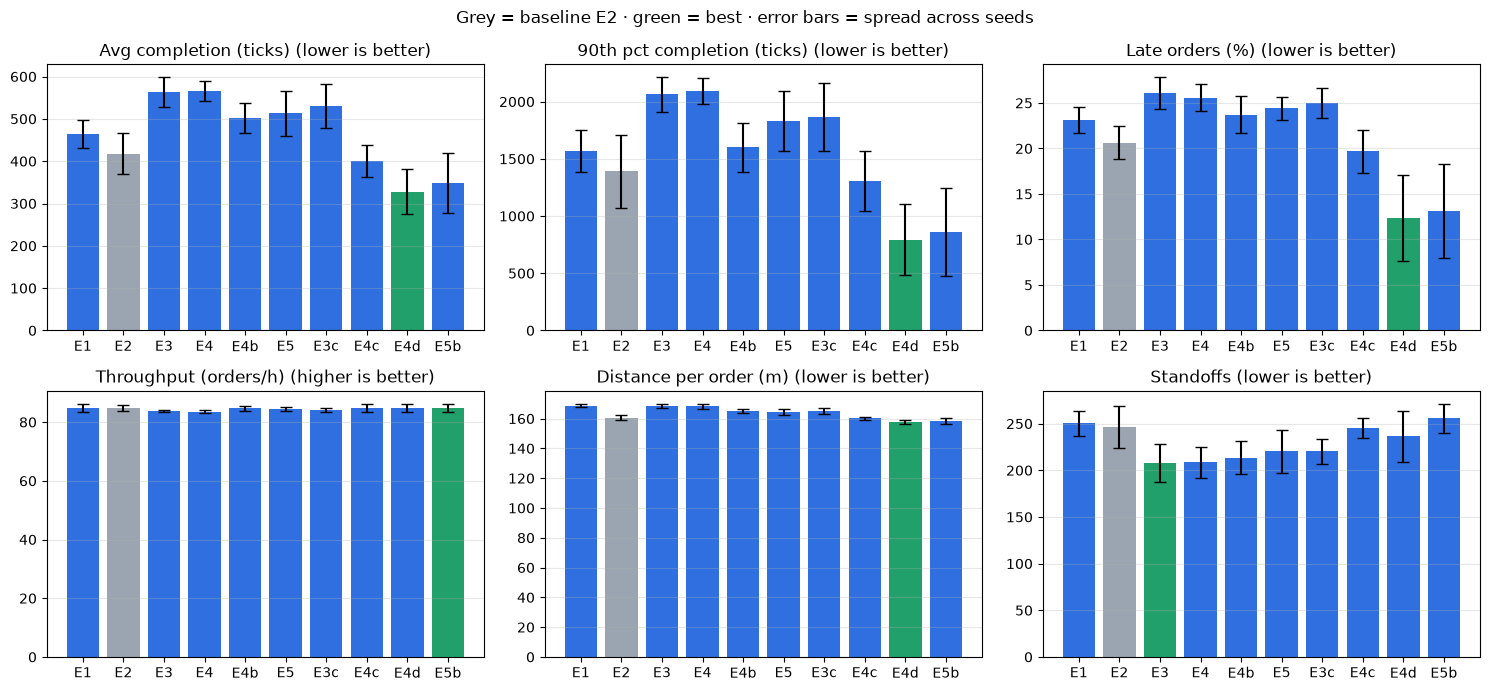

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, kpi in zip(axes.ravel(), ["avg_completion_ticks", "p90_completion_ticks", "late_percent",
                                  "throughput_per_hour", "distance_per_order_m", "blocked_events"], strict=True):  # fmt: skip
    label, lower = KPIS[kpi]
    best = mean[kpi].idxmin() if lower else mean[kpi].idxmax()
    colors = ["#9AA5B1" if e == manifest["baseline"] else "#22A06B" if e == best else "#2F6FE0" for e in order]
    ax.bar(order, mean[kpi], yerr=std[kpi], color=colors, capsize=4)
    ax.set_title(f"{label} ({'lower' if lower else 'higher'} is better)")
    ax.grid(axis="y", alpha=0.3)
fig.suptitle("Grey = baseline E2 · green = best · error bars = spread across seeds")
plt.tight_layout()
plt.show()

## 5. Paired comparison with the baseline (E2)

For every experiment and KPI: the average change vs E2 on the same seeds, in % of the baseline, and on
how many seeds it improved.

In [5]:
pivot = versus.assign(label=versus["kpi"].map(lambda k: KPIS.get(k, (k,))[0]))
pivot = pivot[pivot["kpi"].isin(KPIS)]
pct = pivot.pivot(index="experiment", columns="label", values="change_percent").reindex([e for e in order if e != "E2"])
wins = pivot.pivot(index="experiment", columns="label", values="seeds_improved").reindex(pct.index)
display(pct.round(1).astype(str) + " %")
display(wins)

label,90th pct completion (ticks),Avg completion (ticks),Distance per order (m),Late orders (%),Standoffs,Throughput (orders/h),Wait for a robot (ticks)
experiment,,,,,,,
E1,12.7 %,11.1 %,5.0 %,11.9 %,1.7 %,0.0 %,15.0 %
E3,48.4 %,35.0 %,4.8 %,26.4 %,-15.6 %,-1.1 %,55.7 %
E4,50.6 %,35.5 %,4.7 %,23.9 %,-15.2 %,-1.5 %,57.1 %
E4b,15.0 %,20.2 %,2.7 %,14.9 %,-13.3 %,-0.1 %,31.3 %
E5,31.6 %,22.8 %,2.2 %,18.3 %,-10.3 %,-0.4 %,36.9 %
E3c,34.3 %,27.1 %,2.6 %,21.4 %,-10.4 %,-0.8 %,43.3 %
E4c,-6.0 %,-4.3 %,-0.3 %,-4.5 %,-0.2 %,0.2 %,-7.1 %
E4d,-42.9 %,-21.4 %,-1.8 %,-40.1 %,-3.9 %,0.2 %,-35.6 %
E5b,-38.0 %,-16.5 %,-1.4 %,-36.4 %,4.0 %,0.2 %,-27.4 %


label,90th pct completion (ticks),Avg completion (ticks),Distance per order (m),Late orders (%),Standoffs,Throughput (orders/h),Wait for a robot (ticks)
experiment,,,,,,,
E1,1/5,0/5,0/5,0/5,2/5,1/5,0/5
E3,0/5,0/5,0/5,0/5,4/5,0/5,0/5
E4,0/5,0/5,0/5,0/5,4/5,0/5,0/5
E4b,1/5,0/5,0/5,0/5,5/5,2/5,0/5
E5,0/5,0/5,0/5,0/5,5/5,3/5,0/5
E3c,0/5,0/5,0/5,0/5,4/5,0/5,0/5
E4c,3/5,4/5,3/5,3/5,3/5,3/5,3/5
E4d,5/5,5/5,5/5,5/5,4/5,3/5,5/5
E5b,5/5,5/5,5/5,5/5,2/5,3/5,5/5


## 6. Consistency across seeds

Average completion time per seed: a strategy that is better on every simulated day is a robust improvement, not luck.

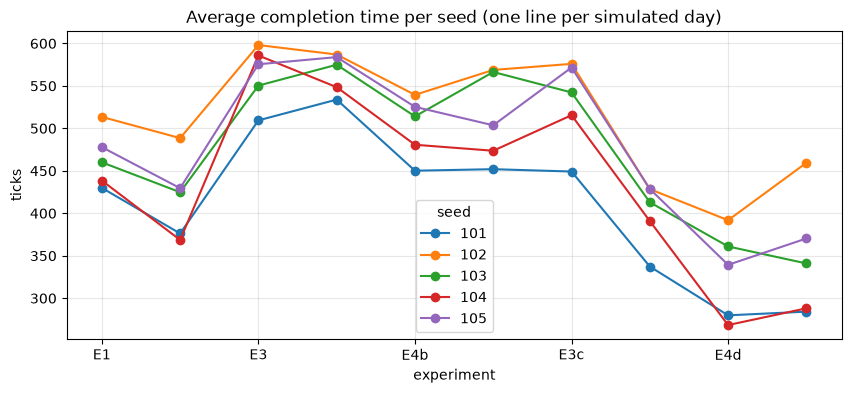

experiment,E1,E2,E3,E4,E4b,E5,E3c,E4c,E4d,E5b
seed,,,,,,,,,,
101,429.9,376.2,509.4,533.8,450.1,451.9,449.2,337.3,279.8,284.2
102,513.5,488.5,598.1,586.9,539.4,568.8,575.9,428.4,391.8,459.4
103,460.0,424.8,550.3,574.9,514.0,566.4,542.2,413.0,361.0,340.9
104,438.5,368.6,585.8,548.5,480.7,473.6,515.5,390.8,268.4,288.1
105,477.9,429.5,575.5,583.9,525.3,503.6,571.6,428.6,339.3,370.3


In [6]:
per_seed = runs.pivot(index="seed", columns="experiment", values="avg_completion_ticks")[order]
per_seed.T.plot(marker="o", figsize=(10, 4), title="Average completion time per seed (one line per simulated day)")
plt.ylabel("ticks")
plt.grid(alpha=0.3)
plt.show()
per_seed.round(1)

## 7. Conclusions

**All results** (mean of 5 simulated days, ticks unless noted, lower is better):

| ID | Strategy | Avg completion | 90th pct | Late % | Wait for robot | Distance/order (m) | Standoffs |
|---|---|---|---|---|---|---|---|
| E1 | Random robot | 464 | 1567 | 23.1 | 272 | 168.7 | 250 |
| E2 | **Baseline**: nearest robot, BFS | 418 | 1390 | 20.6 | 236 | 160.7 | 246 |
| E3 | + A\* traffic-aware | 564 | 2064 | 26.1 | 368 | 168.4 | 208 |
| E3c | + A\* gentle traffic (diag.) | 531 | 1867 | 25.0 | 338 | 164.8 | 220 |
| E4 | + A\* + ETA robot choice | 566 | 2094 | 25.6 | 371 | 168.3 | 209 |
| E4b | + A\* + Hungarian | 502 | 1599 | 23.7 | 310 | 165.1 | 213 |
| E4c | ETA robot choice, BFS (diag.) | 400 | 1307 | 19.7 | 219 | 160.2 | 246 |
| E4d | **Hungarian on predicted times, BFS** | 328 | 793 | 12.4 | 152 | 157.9 | 236 |
| E5 | Everything incl. A\* | 513 | 1830 | 24.4 | 323 | 164.2 | 221 |
| E5b | E4d + demand parking + forecast charging | 349 | 862 | 13.1 | 171 | 158.4 | 256 |

**1. The winner: E4d — assign all waiting orders together (Hungarian algorithm) using the ETA model's
predicted delivery times, with the normal shortest routes.** Compared with today's rules on the same
five days:

- average delivery time **-21.4 % (5/5 days)**
- slowest 10 % of orders **-42.9 % (5/5 days)**
- late orders **-40.1 % (5/5 days)**
- time an order waits for a robot **-35.6 % (5/5 days)**

It wins on **every** simulated day. Throughput is unchanged (the fleet delivers the same orders per
hour; capacity is set by the robots) — the gain is that each order is matched with the robot that will
really finish it soonest, and urgent orders are matched first, so the queue clears faster.

**2. Traffic-aware A\* made things worse** (E3 +35.0 % (0/5 days), even the gentle
version E3c +27.1 % (0/5 days)). It reduced standoffs, but made every trip about 5 %
longer. At peak hours the warehouse is **overloaded** — more than half of an order's time is spent
waiting for a free robot — so robot time is the scarcest resource, and extra metres grow the queue.
Because E4, E4b and E5 also used A\*, it hid the value of the AI assignment until the diagnostic runs
(E4c, E4d) tested assignment with normal routes.

**3. Choosing one robot at a time by predicted finish time** (E4c) helps a little
(-4.3 % (4/5 days)); planning **all waiting orders together** (E4d) helps far more,
because a greedy one-by-one choice can leave later orders with a distant robot.

**4. Demand-aware parking and forecast-driven charging add nothing on top** (E5b
-16.5 % (5/5 days) vs E4d -21.4 % (5/5 days)): when robots are
almost never idle at peaks, where they wait matters little.

**Recommendation:** use **E4d** as the optimised strategy (select it in the app's **Strategy** menu).
Keep E2 as the reference.

**Honest limits:** 5 simulated days per experiment (consistent wins across all 5 days make the main
result reliable, but small differences such as E4c's are within day-to-day variation); one layout and
fleet size; the ETA model was trained on baseline behaviour. The run times in `runs.csv` for a few runs
include a period when the computer was asleep and are not meaningful.